# 05b · IBM hardware: a 20 x 20 kernel block

A kernel block of 20 points is evaluated on an IBM backend and compared with the exact kernel, the noisy simulator and a
fake device model. 20 points give 190 off-diagonal pairs plus 20 diagonal pairs = **210 circuits** in **one PUB**
(one job). The diagonal is measured on purpose: on hardware it is no longer exactly 1, and that is the most direct reading of the device noise.

**Budget.** The free plan gives about 10 minutes of QPU time per month. At 2048 shots this block needs roughly 1 to 3 minutes.
The submit cell is **off by default** (`SUBMIT_TO_HARDWARE = False`). Run everything once with it off (this checks the circuits on the fake device),
then set it to `True`, run the submit cell once, and set it back. The job id is saved to disk, so the result can be fetched later
even after a kernel restart.

Pre-flight checklist (lecture 2): correct on Aer first, `optimization_level = 3`, two-qubit gate count checked, shots chosen deliberately.
Credentials come from the account saved in NB02 (`QiskitRuntimeService(name = "0058-free-ibm")`), never from a token in this notebook.

In [1]:
# Make the project helper package (qsvm_rc) importable from any sub-folder
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "qsvm_rc").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: D:\LUMS PAs\3rd Semester\AI631 - Quantum Machine Learning\Project


In [ ]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from qiskit import transpile
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import SamplerV2
from sklearn.model_selection import LeaveOneOut
from sklearn.svm import SVC

from qsvm_rc import config, data_utils, metrics, models, quantum_kernels

SECTION = config.MAIN_SECTION
RESULTS_DIR = config.section_results_dir(SECTION, "hardware")
JOB_FILE = RESULTS_DIR / "hardware_job.json"

USE_IBM = True # connect and transpile for the real backend (free, no QPU time)
SUBMIT_TO_HARDWARE = False # set True for ONE run of the submit cell, then back to False
HARDWARE_SHOTS = 2048
MAP_NAME = "zz" # the entangling map is the interesting one on hardware
BLOCK_POINTS_PER_GROUP = 5 # SAFE near, UNSAFE near, SAFE far, UNSAFE far

In [ ]:
# Pinned to the settings the submitted job used (job dc04d4eq4uuc73a21gd0), so the saved counts
# are always compared with the matching exact kernel, whatever best_configs.json says later
SPEC = {"kind": "zz", "reps": 2, "entanglement": "linear"}
BANDWIDTH = 0.02 # these are the final ZZ settings
C_VALUE = 10000
print(SPEC, "bandwidth", BANDWIDTH, "C", C_VALUE)

{'kind': 'zz', 'reps': 2, 'entanglement': 'linear'} bandwidth 0.02 C 10000


## 1. The 20 points

Five from each group, all from the training pool (never from the test set): SAFE and UNSAFE within $|r - 1| \le 0.1$ of the boundary,
and SAFE and UNSAFE further away. Saved so the block can be reproduced.

In [4]:
frame = data_utils.load_section(SECTION)
splits = data_utils.load_splits(SECTION)
scaler = data_utils.domain_scaler(SECTION, frame)
test_rows, _ = data_utils.test_indices(splits)
pool = np.setdiff1d(np.arange(len(frame)), test_rows)

labels = frame["label"].to_numpy()
distance = np.abs(frame["ratio"].to_numpy() - 1)
block_rng = np.random.default_rng(config.run_seed(config.SEED, 77))
groups = {
    "SAFE near": pool[(labels[pool] == 1) & (distance[pool] <= 0.1)],
    "UNSAFE near": pool[(labels[pool] == -1) & (distance[pool] <= 0.1)],
    "SAFE far": pool[(labels[pool] == 1) & (distance[pool] > 0.3)],
    "UNSAFE far": pool[(labels[pool] == -1) & (distance[pool] > 0.3)],
}
block_rows = np.concatenate([block_rng.choice(candidates, size = BLOCK_POINTS_PER_GROUP, replace = False) for candidates in groups.values()])
block_groups = np.repeat(list(groups), BLOCK_POINTS_PER_GROUP)
x_block, y_block = data_utils.features_and_labels(frame, block_rows, scaler)
encoded_block = models.encode(x_block, SPEC, BANDWIDTH)

block_table = frame.iloc[block_rows][["pu_kN", "ex_mm", "ey_mm", "status", "ratio"]].assign(group = block_groups)
block_table.to_csv(RESULTS_DIR / "block_points.csv")
block_table

,pu_kN,ex_mm,ey_mm,status,ratio,group
4732,4750,10.0,290.0,SAFE,0.930960,SAFE near
93558,4250,300.0,160.0,SAFE,0.909711,SAFE near
137704,3500,390.0,185.0,SAFE,0.903476,SAFE near
82109,4000,275.0,230.0,SAFE,0.956152,SAFE near
83702,4750,280.0,150.0,SAFE,0.962593,SAFE near
147933,3500,410.0,230.0,UNSAFE,1.005584,UNSAFE near
40405,5750,160.0,205.0,UNSAFE,1.091688,UNSAFE near
21641,5250,80.0,275.0,UNSAFE,1.070201,UNSAFE near
117360,5500,350.0,60.0,UNSAFE,1.053819,UNSAFE near
149157,4750,415.0,80.0,UNSAFE,1.055554,UNSAFE near


In [5]:
pairs = quantum_kernels.pair_list(encoded_block, include_diagonal = True)
print("Circuits (pairs including the diagonal):", len(pairs))
exact_block = quantum_kernels.exact_gram(SPEC, encoded_block)
print("Exact block diagnostics:", {key: round(value, 4) for key, value in metrics.kernel_diagnostics(exact_block, y_block).items()})

Circuits (pairs including the diagonal): 210
Exact block diagnostics: {'mean_offdiag': 0.9688, 'std_offdiag': 0.0308, 'min_eigenvalue': 0.0, 'target_alignment': 0.0075}


## 2. Circuits and a runner shared by every backend

The same `SamplerV2` code runs the fake device locally and the real device (NB02: same code, two backends).
Values are bound **by parameter name**: the first point goes into `p1[k]`, the second into `p2[k]`.

In [6]:
overlap = quantum_kernels.overlap_template(quantum_kernels.build_feature_map(SPEC))


def parameter_matrix(circuit, pair_indices, encoded):
    """One row per pair, columns in the circuit's own parameter order."""
    first, second = quantum_kernels.overlap_parameters(circuit)
    column_of = {parameter: position for position, parameter in enumerate(circuit.parameters)}
    values = np.zeros((len(pair_indices), len(column_of)))
    for row, (i, j) in enumerate(pair_indices):
        for k in range(len(first)):
            values[row, column_of[first[k]]] = encoded[i, k]
            values[row, column_of[second[k]]] = encoded[j, k]
    return values


def counts_to_block(counts_list, pair_indices, size, shots):
    """Fill the symmetric kernel block from the all-zero frequencies."""
    block = np.zeros((size, size))
    for (i, j), counts in zip(pair_indices, counts_list):
        value = counts.get("0" * 3, 0) / shots
        block[i, j] = value
        block[j, i] = value
    return block


def sampler_counts(job_result, number_of_pairs):
    bit_array = job_result[0].data.meas
    return [bit_array.get_counts(index) for index in range(number_of_pairs)]


def isa_resources(circuit, label, shots):
    resources = quantum_kernels.circuit_resources(circuit)
    operations = dict(circuit.count_ops())
    return {"target": label, **resources, "shots": shots, "circuits": len(pairs),
            "ops": ", ".join(f"{name}:{count}" for name, count in operations.items())}

## 3. Simulator references for the same 210 circuits

In [7]:
kernels = {"exact": exact_block}
resource_rows = []

ideal_simulator = AerSimulator()
ideal_circuit = transpile(overlap, ideal_simulator)
kernels["aer shots only"] = quantum_kernels.sampled_gram(ideal_circuit, ideal_simulator, encoded_block, shots = HARDWARE_SHOTS,
                                                         seed = config.SEED, include_diagonal = True)

noisy_circuit = quantum_kernels.transpile_for_simulation(overlap)
noisy_backend = quantum_kernels.noisy_simulator(one_qubit_error = 0.001, two_qubit_error = 0.01, readout_error = 0.02)
kernels["aer depolarizing"] = quantum_kernels.sampled_gram(noisy_circuit, noisy_backend, encoded_block, shots = HARDWARE_SHOTS,
                                                           seed = config.SEED, include_diagonal = True)
resource_rows.append(isa_resources(noisy_circuit, "Aer basis rz sx x cx", HARDWARE_SHOTS))
print({name: round(float(np.mean(np.abs(kernel - exact_block))), 4) for name, kernel in kernels.items()})

{'exact': 0.0, 'aer shots only': 0.0027, 'aer depolarizing': 0.1519}


## 4. Connect to IBM and transpile (no QPU time used)

In [8]:
service = None
backend = None
if USE_IBM:
    from qiskit_ibm_runtime import QiskitRuntimeService
    try:
        service = QiskitRuntimeService(name = config.IBM_ACCOUNT_NAME)
        try:
            backend = service.backend(config.IBM_BACKEND_NAME)
        except Exception as error:
            print(f"{config.IBM_BACKEND_NAME} not available ({error}), using the least busy device")
            backend = service.least_busy(operational = True, simulator = False)
        status = backend.status()
        print("Backend:", backend.name, "| qubits:", backend.num_qubits, "| pending jobs:", status.pending_jobs)
    except Exception as error:
        print("IBM connection failed, continuing with the fake device only:", error)

qiskit_runtime_service.__init__:WARNING:2026-11-20 18:07:25,223: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: instance-1. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-20 18:07:25,227: Using instance: instance-1, plan: open


Backend: ibm_fez | qubits: 156 | pending jobs: 0


In [9]:
fake_backend = quantum_kernels.fake_device_backend()
target_backend = backend if backend is not None else fake_backend
pass_manager = generate_preset_pass_manager(optimization_level = 3, backend = target_backend, seed_transpiler = config.SEED)
isa_overlap = pass_manager.run(overlap)
isa_values = parameter_matrix(isa_overlap, pairs, encoded_block)

print("Transpiled for:", target_backend.name)
print("Physical qubits:", isa_overlap.layout.final_index_layout() if isa_overlap.layout is not None else "n/a")
resource_rows.append(isa_resources(isa_overlap, f"{target_backend.name} ISA (opt level 3)", HARDWARE_SHOTS))
print(pd.DataFrame(resource_rows).to_string(index = False))

Transpiled for: ibm_fez
Physical qubits: [24, 23, 22]
                   target  qubits_used  depth  two_qubit_gates  total_gates  shots  circuits                                       ops
     Aer basis rz sx x cx            3     39               14           70   2048       210 rz:44, cx:14, sx:12, measure:3, barrier:1
ibm_fez ISA (opt level 3)            3     80               14          109   2048       210 rz:59, sx:36, cz:14, measure:3, barrier:1


## 5. Dry run on the fake device (local, same ISA circuit and the same SamplerV2 code)

In [10]:
fake_pass_manager = generate_preset_pass_manager(optimization_level = 3, backend = fake_backend, seed_transpiler = config.SEED)
fake_isa = fake_pass_manager.run(overlap)
fake_values = parameter_matrix(fake_isa, pairs, encoded_block)
start = time.time()
fake_result = SamplerV2(mode = fake_backend).run([(fake_isa, fake_values, HARDWARE_SHOTS)]).result()
fake_counts = sampler_counts(fake_result, len(pairs))
kernels[f"fake {fake_backend.name}"] = counts_to_block(fake_counts, pairs, len(block_rows), HARDWARE_SHOTS)
resource_rows.append(isa_resources(fake_isa, f"{fake_backend.name} ISA (opt level 3)", HARDWARE_SHOTS))
print(f"Fake device run: {time.time() - start:.1f} s")
print("Fake device diagonal (1 without noise):", np.round(np.diag(kernels[f"fake {fake_backend.name}"]), 3))

Fake device run: 20.6 s
Fake device diagonal (1 without noise): [0.947 0.958 0.96  0.956 0.96  0.954 0.956 0.966 0.958 0.958 0.96  0.953
 0.958 0.952 0.959 0.962 0.96  0.96  0.958 0.962]


## 6. Submit to the real device (one job, one PUB)

Rough QPU time: circuits x shots x (repetition delay + circuit duration), about 210 x 2048 x 0.3 ms, i.e. a couple of minutes.

In [16]:
print(f"Circuits {len(pairs)}, shots {HARDWARE_SHOTS}, rough QPU estimate {len(pairs) * HARDWARE_SHOTS * 3e-4 / 60:.1f} min")
if SUBMIT_TO_HARDWARE and backend is not None:
    if JOB_FILE.exists():
        print("A job id is already saved in", JOB_FILE, "- delete that file to submit again.")
    else:
        sampler = SamplerV2(mode = backend)
        sampler.options.default_shots = HARDWARE_SHOTS
        try:
            sampler.options.dynamical_decoupling.enable = True
            sampler.options.dynamical_decoupling.sequence_type = "XY4"
        except AttributeError:
            print("Dynamical decoupling option not available in this runtime version")
        job = sampler.run([(isa_overlap, isa_values, HARDWARE_SHOTS)])
        job_info = {"job_id": job.job_id(), "backend": backend.name, "shots": HARDWARE_SHOTS, "pairs": [list(pair) for pair in pairs],
                    "block_rows": block_rows.tolist(), "spec": SPEC, "bandwidth": BANDWIDTH, "C": C_VALUE,
                    "submitted": time.strftime("%Y-%m-%d %H:%M:%S")}
        with open(JOB_FILE, "w") as handle:
            json.dump(job_info, handle, indent = 2)
        print("Submitted job", job.job_id(), "- saved to", JOB_FILE)
else:
    print("Not submitting (SUBMIT_TO_HARDWARE is False or no IBM backend).")

Circuits 210, shots 2048, rough QPU estimate 2.2 min
Submitted job dc04d4eq4uuc73a21gd0 - saved to D:\LUMS PAs\3rd Semester\AI631 - Quantum Machine Learning\Project\results\3x2\hardware\hardware_job.json


## 7. Fetch the hardware result (works after a restart too)

In [18]:
hardware_counts = None
counts_file = RESULTS_DIR / "hardware_counts.json"
if counts_file.exists():
    with open(counts_file) as handle:
        hardware_counts = json.load(handle)
    print("Loaded saved hardware counts")
elif JOB_FILE.exists() and service is not None:
    with open(JOB_FILE) as handle:
        job_info = json.load(handle)
    job = service.job(job_info["job_id"])
    print("Job", job_info["job_id"], "status:", job.status())
    status = str(job.status())
    if status in ("DONE", "JobStatus.DONE"):
        hardware_counts = sampler_counts(job.result(), len(pairs))
        with open(counts_file, "w") as handle:
            json.dump(hardware_counts, handle)
        try:
            print("Usage:", job.metrics().get("usage"))
        except Exception as error:
            print("Usage not available:", error)
    elif status in ("ERROR", "CANCELLED", "JobStatus.ERROR", "JobStatus.CANCELLED"):
        print("The job failed or was cancelled. Delete", JOB_FILE, "and submit again.")
    else:
        print("Not finished yet (queued or running). Re-run this cell later.")
else:
    print("No hardware job yet.")

if hardware_counts is not None:
    kernels["IBM hardware"] = counts_to_block(hardware_counts, pairs, len(block_rows), HARDWARE_SHOTS)
    np.save(RESULTS_DIR / "hardware_kernel_block.npy", kernels["IBM hardware"])

Job dc04d4eq4uuc73a21gd0 status: DONE
Usage: {'qpu_charge_time_seconds': 114, 'value': 1.89985, 'unit': 'resource_units', 'status': 'complete', 'details': [{'value': 1.89985, 'unit': 'resource_units', 'metric': {'id': 'caffe3ca-729c-5750-8777-df63bbf8bfd9', 'value': 114}}]}


## 8. Compare the kernels

In [19]:
def leave_one_out(block, labels, c_value):
    """Leave-one-out labels and decision values with a precomputed kernel block."""
    predictions = np.zeros(len(labels))
    decisions = np.zeros(len(labels))
    symmetric = (block + block.T) / 2
    for fit_rows, check_rows in LeaveOneOut().split(symmetric):
        classifier = SVC(kernel = "precomputed", C = c_value).fit(symmetric[np.ix_(fit_rows, fit_rows)], labels[fit_rows])
        decisions[check_rows] = classifier.decision_function(symmetric[np.ix_(check_rows, fit_rows)])
        predictions[check_rows] = classifier.predict(symmetric[np.ix_(check_rows, fit_rows)])
    return predictions, decisions


off_diagonal = np.logical_not(np.eye(len(block_rows), dtype = bool))
exact_loo, exact_decision = leave_one_out(exact_block, y_block, C_VALUE)
comparison_rows = []
for name, block in kernels.items():
    loo_predictions, loo_decisions = leave_one_out(block, y_block, C_VALUE)
    comparison_rows.append({
        "kernel": name,
        "mae_offdiag_vs_exact": float(np.mean(np.abs(block - exact_block)[off_diagonal])),
        "diagonal_mean": float(np.mean(np.diag(block))),
        "mean_offdiag": float(np.mean(block[off_diagonal])),
        "lambda_fit": quantum_kernels.global_depolarizing_fit(block, exact_block),
        "min_eigenvalue": metrics.kernel_diagnostics(block)["min_eigenvalue"],
        "loo_accuracy": float(np.mean(loo_predictions == y_block)),
        "loo_agreement_with_exact": float(np.mean(loo_predictions == exact_loo)),
        "loo_decision_correlation": float(np.corrcoef(loo_decisions, exact_decision)[0, 1]),
    })
hardware_comparison = pd.DataFrame(comparison_rows)
hardware_comparison.to_csv(RESULTS_DIR / "kernel_block_comparison.csv", index = False)
pd.DataFrame(resource_rows).to_csv(RESULTS_DIR / "hardware_resources.csv", index = False)
hardware_comparison.round(4)

,kernel,mae_offdiag_vs_exact,diagonal_mean,mean_offdiag,lambda_fit,min_eigenvalue,loo_accuracy,loo_agreement_with_exact,loo_decision_correlation
0,exact,0.0000,1.0000,0.9688,1.0000,0.0000,0.80,1.00,1.0000
1,aer shots only,0.0028,1.0000,0.9682,0.9994,-0.0285,0.60,0.50,0.6843
2,aer depolarizing,0.1515,0.8401,0.8173,0.8205,-0.0703,0.50,0.40,0.4428
3,fake fake_fez,0.0404,0.9579,0.9284,0.9521,-0.0396,0.50,0.60,0.7807
4,IBM hardware,0.0838,0.9133,0.8850,0.9007,-0.0530,0.65,0.55,0.4934


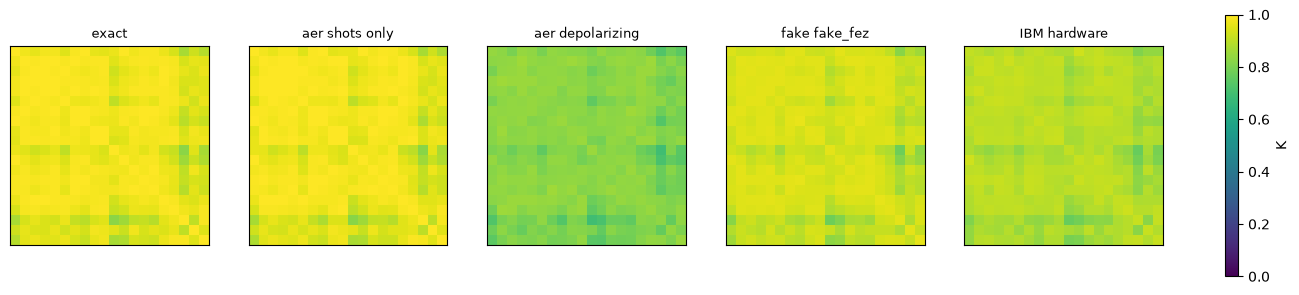

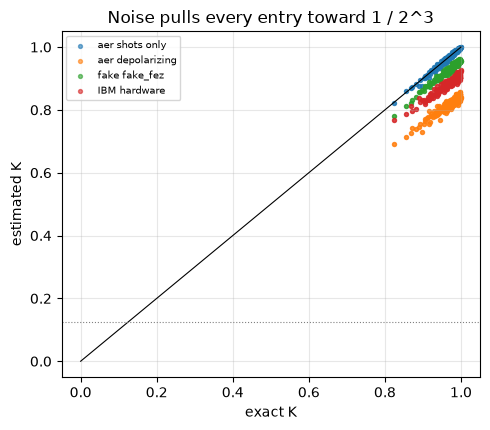

In [20]:
figure, axes = plt.subplots(1, len(kernels), figsize = (3.2 * len(kernels), 3.4))
for axis, (name, block) in zip(np.atleast_1d(axes), kernels.items()):
    image = axis.imshow(block, vmin = 0, vmax = 1, cmap = "viridis")
    axis.set_title(name, fontsize = 9)
    axis.set_xticks([])
    axis.set_yticks([])
figure.colorbar(image, ax = axes, fraction = 0.02, label = "K")
figure.savefig(config.figures_dir() / "hardware_kernel_blocks.png", dpi = 200)
plt.show()

figure = plt.figure(figsize = (5, 4.4))
for name, block in kernels.items():
    if name == "exact":
        continue
    plt.scatter(exact_block[off_diagonal], block[off_diagonal], s = 8, alpha = 0.6, label = name)
plt.plot([0, 1], [0, 1], color = "k", linewidth = 0.8)
plt.axhline(1 / 8, color = "grey", linestyle = ":", linewidth = 0.8)
plt.xlabel("exact K")
plt.ylabel("estimated K")
plt.legend(fontsize = 7)
plt.grid(alpha = 0.3)
plt.title("Noise pulls every entry toward 1 / 2^3")
plt.tight_layout()
figure.savefig(config.figures_dir() / "hardware_kernel_scatter.png", dpi = 200)
plt.show()

**What to write up.** Report the resource table (qubits, depth, two-qubit gates, shots, circuits), the fitted $\lambda$ for
the hardware and the fake device, the measured diagonal, and whether the leave-one-out labels moved. A hardware $\lambda$ close to the
fake device's says the noise model is a fair stand-in, which justifies the larger noise study in 05a.

Next: `06_analysis/01_final_tables_and_falsifier.ipynb`.